# wildfire API tutorial

This notebook demonstrates the **saved-model wildfire API and the heat-flux API** with the included FishCreek data. Run the cells from top to bottom using Python 3.12. Running this notebook creates a fresh output directory. The active default is the supported 5×5 checkpoint from the completed `20261010_categorical_balanced_benchmark` run. Earlier rendered previews and stored outputs are historical and use their recorded model; equal coverage counts do not imply equal weights or probabilities.

Both prediction APIs return **`(prediction_matrix, coordinate_matrix)`**. Every coordinate pair is the geographic **cell center**, ordered **`(latitude, longitude)`**, in **WGS84 degrees (EPSG:4326)**. Coordinates are static across time.

| Input organization | Wildfire prediction | Coordinates |
| --- | --- | --- |
| Raw spatial snapshot | `(1, H, W)` | `(H, W, 2)` |
| One-step dataset sequence | `(1, 1, H, W)` | `(H, W, 2)` |
| One sequence | `(T, 1, H, W)` | `(H, W, 2)` |
| Collated batch | `(B, T, 1, H, W)` | `(B, H, W, 2)` |
| One heat snapshot | `(H, W)` | `(H, W, 2)` |

`B` is batch size, `T` is the number of time steps, `H` is the number of rows, and `W` is the number of columns. Wildfire predictions remain on the model device; their coordinates are CPU `torch.float64` tensors. Heat matrices and coordinates are NumPy arrays.

**What the example establishes:** how to load data and model parameters, call each interface, inspect missingness, plot outputs, and verify exports and save/reload. The data are retrospective burned-area reconstructions. This tutorial does not establish operational forecast skill or heat-flux accuracy against measurements. The physical heat parameters below are illustrative assumptions.

[Maintained API guide](README.md#python-interfaces) · [Heat guide](README.md#heat-guide)

## 1. Select the Python environment and workspace

From the directory containing `README.md` and `pyproject.toml`, the following shell commands install the notebook dependencies and open this file:

```sh
python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install -e '.[notebook]'
python -m jupyter lab api_tutorial.ipynb
```

Reuse an existing compatible environment when available. Select its Python 3.12 kernel in Jupyter. The notebook checks the actual interpreter below. It uses the workspace source directly, so edits to the API are reflected after a kernel restart.

The workspace is found by searching the kernel's working directory and its parents. If you launch Jupyter elsewhere, set the `WILDFIREGUARDIAN_ROOT` environment variable to the workspace path before opening it.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import tempfile
from datetime import datetime, timedelta, timezone
from importlib.metadata import version

assert sys.version_info[:2] == (3, 12), "Select the workspace's Python 3.12 kernel."
candidates = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("WILDFIREGUARDIAN_ROOT"):
    candidates.insert(0, Path(os.environ["WILDFIREGUARDIAN_ROOT"]).expanduser())
ROOT = next((p.resolve() for p in candidates
             if (p / 'pyproject.toml').is_file()
             and (p / 'wildfire').is_dir()), None)
assert ROOT is not None, "Set WILDFIREGUARDIAN_ROOT to the directory containing the README."
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from wildfire import load_model
from wildfire import load_data
from wildfire import collate_fire_sequences

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160, "font.size": 10})
RUNS_DIR = ROOT / "demonstration/api_tutorial/runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = Path(tempfile.mkdtemp(prefix="run-", dir=RUNS_DIR))
print("Python:", sys.executable)
print("Workspace:", ROOT)
print("Outputs for this execution:", OUTPUT_DIR)
display(pd.DataFrame({"package": ["numpy", "torch", "pandas", "pyproj", "rasterio"],
                      "version": [version(p) for p in ["numpy", "torch", "pandas", "pyproj", "rasterio"]]}))

Python: /Users/movinggk/Documents/영재멘토/WildfireGuardian/.venv/bin/python
Workspace: /Users/movinggk/Documents/영재멘토/WildfireGuardian
Outputs for this execution: /Users/movinggk/Documents/영재멘토/WildfireGuardian/demonstration/api_tutorial/runs/run-hn5x0et5


,package,version
0,numpy,1.26.4
1,torch,2.5.1
2,pandas,2.2.3
3,pyproj,3.7.0
4,rasterio,1.4.3


## 2. Load a saved model and inspect its contract

`load_model` restores parameters, training-only normalization statistics, channel order, and categorical vocabulary. This example imports `DEFAULT_CHECKPOINT` from `wildfire.paths` and loads the **nonnegative exponential 5×5 model** retained in `20261010_categorical_balanced_benchmark` (`k5_legacy_02_lr0.1_warmup_cosine`). Its probability describes first new cumulative burning during the next exact hour.

Keep the saved channel order and raw physical units. Do not normalize the environmental values yourself. `device="cpu"` makes the example portable; `"auto"` chooses an available supported accelerator. The trained endpoint is `dt_hours=1.0`; other horizons only rescale the frozen rate and have not been separately validated.

In [2]:
DATA_ROOT = ROOT / 'data/environment'
from wildfire.paths import DEFAULT_CHECKPOINT
CHECKPOINT = DEFAULT_CHECKPOINT
EVENT = "WY-BTF-002416_FishCreek"
CUTOFF = "2024-08-23T00:00:00Z"
DEVICE = "cpu"
assert DATA_ROOT.is_dir() and CHECKPOINT.is_file()
model = load_model(CHECKPOINT, device=DEVICE)
display(pd.DataFrame([{
    "family": model.family, "device": str(model.device),
    "kernel_size": model.contract["kernel_size"], "channels": len(model.channel_names),
    "checkpoint_sha256": model.checkpoint_sha256,
}]))
display(pd.DataFrame({"channel_index": range(len(model.channel_names)),
                      "channel_name": model.channel_names}))

,family,device,kernel_size,channels,checkpoint_sha256
0,exponential,cpu,5,19,b985b5bf0bd6f218e2623a8ffdcf27d742944dfbb60a8f...


,channel_index,channel_name
0,0,weather.temperature_2m
1,1,weather.wind_eastward_10m
2,2,weather.wind_northward_10m
3,3,terrain.slope_degrees
4,4,vegetation.tree_cover_percent
5,5,biome.biome_class=1
6,6,biome.biome_class=2
7,7,biome.biome_class=3
8,8,biome.biome_class=4
9,9,biome.biome_class=5


## 3. Read one aligned snapshot

Use **`model.load_data`** for inference: it fixes the checkpoint's channel order and categorical vocabulary. The context manager closes raster readers while leaving returned tensors usable. `sequence_length=1` retains one explicit time step.

The dataset also contains retrospective arrival and outcome fields. `predict_sample` uses the current burned state, current environmental inputs, their masks, and spatial metadata; it does not consume future labels. The reconstructed current state is still retrospective evidence.

`burned_area_valid` and `feature_valid` describe observations/input availability. `pixel_valid` describes spatial padding; `time_valid` describes temporal padding. Numeric zero does not replace any of these masks.

In [3]:
selection = dict(events=[EVENT], sequence_length=1, time_range=(CUTOFF, CUTOFF))
with model.load_data(DATA_ROOT, **selection) as dataset:
    assert len(dataset) == 1, "Choose one event and one full-grid cutoff."
    sample = dataset[0]
assert tuple(sample["channel_names"]) == model.channel_names
H, W = sample["burned_area"].shape[-2:]
display(pd.DataFrame([
    {"object": "burned_area", "shape": tuple(sample["burned_area"].shape)},
    {"object": "features", "shape": tuple(sample["features"].shape)},
    {"object": "pixel_valid", "shape": tuple(sample["pixel_valid"].shape)},
    {"object": "time_valid", "shape": tuple(sample["time_valid"].shape)},
    {"object": "source projected coordinates", "shape": tuple(sample["coordinates"].shape)},
]))
print("Event:", sample["event_id"], "| cutoff:", CUTOFF, "| source EPSG:", int(sample["epsg"]))

,object,shape
0,burned_area,"(1, 1, 103, 73)"
1,features,"(1, 19, 103, 73)"
2,pixel_valid,"(1, 103, 73)"
3,time_valid,"(1,)"
4,source projected coordinates,"(2, 103, 73)"


Event: WY-BTF-002416_FishCreek | cutoff: 2024-08-23T00:00:00Z | source EPSG: 5070


## 4. Predict and read the static Earth coordinates

The regular result is a tuple. For a sequence, `probability[t, 0, row, column]` and `coordinates[row, column]` refer to the same cell. There is **no `T` dimension or singleton channel dimension in coordinates**.

Coordinates come from the affine grid and source CRS, converted to WGS84. They identify representative cell centers, not measured flame positions or a subcell burned perimeter. Unknown predictions retain real coordinates; spatially padded cells have `(NaN, NaN)` coordinates. Temporal padding does not alter the coordinate matrix.

In [4]:
probability_tensor, coordinate_tensor = model.predict_sample(sample)
probability = probability_tensor.cpu().numpy()
coordinates = coordinate_tensor.numpy()
assert probability.shape == (1, 1, H, W)
assert coordinates.shape == (H, W, 2)
assert coordinate_tensor.dtype == torch.float64 and coordinate_tensor.device.type == "cpu"
display(pd.DataFrame([
    {"output": "probability", "shape": probability.shape, "meaning": "next-hour new-burn probability"},
    {"output": "coordinates", "shape": coordinates.shape, "meaning": "latitude, longitude; WGS84 degrees"},
]))
row, column = H // 2, W // 2
latitude, longitude = coordinates[row, column]
print(f"Cell row={row}, column={column}: latitude={latitude:.8f}, longitude={longitude:.8f}")
print("Probability at this cell:", probability[0, 0, row, column])

,output,shape,meaning
0,probability,"(1, 1, 103, 73)",next-hour new-burn probability
1,coordinates,"(103, 73, 2)","latitude, longitude; WGS84 degrees"


Cell row=51, column=36: latitude=43.60520077, longitude=-110.07797536
Probability at this cell: 0.0


### 4.1 Inspect probability and rate validity

`predict_sample_details` returns `probability`, `valid`, `rate`, and `rate_valid`. Rates have units h⁻¹; use `probability` for probability and heat calculations.

This example has many unavailable predictions because required local context is incomplete. A known-unburned target with a complete source neighborhood in which every source is known unburned receives a valid structural zero when the required input context is available, even though training and evaluation use a burned-neighbor-contact cohort. No known burned neighbor is insufficient to establish zero when one or more source states are unknown. Coverage counts do not measure forecast accuracy; retain unavailable values as NaN. The saved executed outputs record the earlier inference policy; rerun the notebook to produce current predictions.

In [5]:
details = model.predict_sample_details(sample)
valid = details.valid.cpu().numpy()
diagnostic_name = "rate"
diagnostic = getattr(details, diagnostic_name).cpu().numpy()
torch.testing.assert_close(probability_tensor, details.probability, rtol=0, atol=0, equal_nan=True)
assert np.isnan(probability[~valid]).all()
assert np.isfinite(probability[valid]).all()
assert np.all((probability[valid] >= 0) & (probability[valid] <= 1))
display(pd.DataFrame([{
    "known_predictions": int(valid.sum()), "unavailable_predictions": int((~valid).sum()),
    "total_cells": H * W, "minimum_known_probability": float(probability[valid].min()),
    "maximum_known_probability": float(probability[valid].max()),
}]))

real_unknown = (~valid[0, 0]) & sample["pixel_valid"][0].numpy()
if real_unknown.any():
    unknown_row, unknown_column = np.argwhere(real_unknown)[0]
    assert np.isfinite(coordinates[unknown_row, unknown_column]).all()
    print("Unavailable prediction at a real cell:", (int(unknown_row), int(unknown_column)))
    print("Its retained latitude/longitude:", coordinates[unknown_row, unknown_column])

,known_predictions,unavailable_predictions,total_cells,minimum_known_probability,maximum_known_probability
0,1246,6273,7519,0.0,0.088771


Unavailable prediction at a real cell: (0, 0)
Its retained latitude/longitude: [  43.75670953 -110.2796554 ]


### 4.2 Call the API with your own arrays

`predict` accepts the same current tensors and boolean masks plus `affine_transform` and the source `epsg`. The six affine coefficients `(a, b, c, d, e, f)` describe pixel **corners**; the API converts cell centers using offsets `(column + 0.5, row + 0.5)`.

`predict_details` needs no geographic metadata. `predict_proba` returns only probabilities, without coordinates or diagnostic fields. The assertions below verify that the convenience methods agree with the tuple interface.

In [6]:
raw_probability, raw_coordinates = model.predict(
    sample["burned_area"], sample["features"],
    channel_names=sample["channel_names"],
    burned_area_valid=sample["burned_area_valid"], feature_valid=sample["feature_valid"],
    affine_transform=sample["affine_transform"], epsg=sample["epsg"],
    pixel_valid=sample["pixel_valid"],
)
probability_only = model.predict_proba(
    sample["burned_area"], sample["features"], channel_names=model.channel_names,
    burned_area_valid=sample["burned_area_valid"], feature_valid=sample["feature_valid"],
)
for other in (raw_probability, probability_only):
    torch.testing.assert_close(other, probability_tensor, rtol=0, atol=0, equal_nan=True)
torch.testing.assert_close(raw_coordinates, coordinate_tensor, rtol=0, atol=0, equal_nan=True)
print("Raw-array, sample, and probability-only interfaces agree exactly.")

Raw-array, sample, and probability-only interfaces agree exactly.


## 5. Plot probabilities and their geographic placement

The left panel uses row/column indices and displays unavailable predictions in gray. The right panel plots the actual WGS84 cell centers, with the full grid in gray and available predictions in color. It does not approximate the curved geographic mesh as an affine latitude/longitude rectangle. No online basemap is needed.

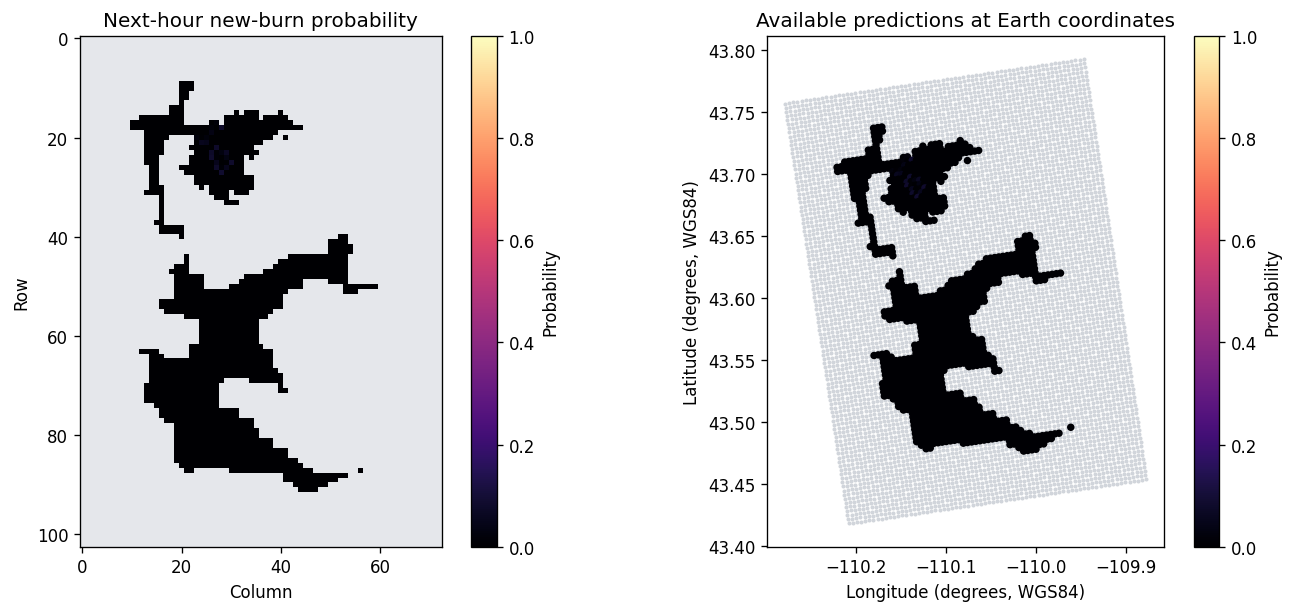

In [7]:
probability_map = np.ma.masked_where(~valid[0, 0], probability[0, 0])
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("#e5e7eb")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
image = axes[0].imshow(probability_map, vmin=0, vmax=1, cmap=cmap)
axes[0].set(title="Next-hour new-burn probability", xlabel="Column", ylabel="Row")
fig.colorbar(image, ax=axes[0], label="Probability")
spatial = sample["pixel_valid"][0].numpy()
axes[1].scatter(coordinates[..., 1][spatial], coordinates[..., 0][spatial],
                c="#d1d5db", s=2, rasterized=True, label="Grid cells")
known = valid[0, 0] & spatial
points = axes[1].scatter(coordinates[..., 1][known], coordinates[..., 0][known],
                         c=probability[0, 0][known], s=12, vmin=0, vmax=1,
                         cmap="magma", rasterized=True)
axes[1].set(title="Available predictions at Earth coordinates",
            xlabel="Longitude (degrees, WGS84)", ylabel="Latitude (degrees, WGS84)")
axes[1].set_aspect(1 / np.cos(np.deg2rad(np.nanmean(coordinates[..., 0]))))
fig.colorbar(points, ax=axes[1], label="Probability")
fig.savefig(OUTPUT_DIR / "probability_and_coordinates.png", bbox_inches="tight")
plt.show()
plt.close(fig)

## 6. Sequences and batches: coordinates stay static

The two-step sequence below contains current inputs at two UTC cutoffs. Each predicted slice forecasts its own following hour; the model is not being rolled forward recursively. Probabilities have shape `(T, 1, H, W)`, while one `(H, W, 2)` coordinate matrix serves every time step.

`collate_fire_sequences` adds the batch dimension and handles spatial padding for varying event grids. Here a batch of size one demonstrates the contract `(B, T, 1, H, W)` with coordinates `(B, H, W, 2)`. Different batch items may have different spatial grids and coordinate systems.

In [8]:
SECOND_CUTOFF = (datetime.fromisoformat(CUTOFF.replace("Z", "+00:00"))
                 + timedelta(hours=1)).strftime("%Y-%m-%dT%H:%M:%SZ")
with model.load_data(DATA_ROOT, events=[EVENT], sequence_length=2,
                     time_range=(CUTOFF, SECOND_CUTOFF)) as dataset:
    assert len(dataset) == 1
    sequence = dataset[0]
sequence_probability, sequence_coordinates = model.predict_sample(sequence)
assert sequence_probability.shape == (2, 1, H, W)
assert sequence_coordinates.shape == (H, W, 2)
torch.testing.assert_close(sequence_coordinates, coordinate_tensor, rtol=0, atol=0, equal_nan=True)
torch.testing.assert_close(sequence_probability[0], probability_tensor[0], rtol=0, atol=0, equal_nan=True)

batch = collate_fire_sequences([sequence])
batch_probability, batch_coordinates = model.predict_sample(batch)
assert batch_probability.shape == (1, 2, 1, H, W)
assert batch_coordinates.shape == (1, H, W, 2)
torch.testing.assert_close(batch_coordinates[0], coordinate_tensor, rtol=0, atol=0, equal_nan=True)
display(pd.DataFrame([
    {"case": "one snapshot", "prediction": tuple(probability_tensor.shape), "coordinates": tuple(coordinate_tensor.shape)},
    {"case": "two-step sequence", "prediction": tuple(sequence_probability.shape), "coordinates": tuple(sequence_coordinates.shape)},
    {"case": "batch of one sequence", "prediction": tuple(batch_probability.shape), "coordinates": tuple(batch_coordinates.shape)},
]))

,case,prediction,coordinates
0,one snapshot,"(1, 1, 103, 73)","(103, 73, 2)"
1,two-step sequence,"(2, 1, 103, 73)","(103, 73, 2)"
2,batch of one sequence,"(1, 2, 1, 103, 73)","(1, 103, 73, 2)"


### 6.1 Spatial patches and padding

`patch_size` requests rectangular spatial patches without resizing the raster. The affine transform is shifted to the patch origin. In an edge patch, `pixel_valid=False` marks cells beyond the real grid and those cells receive NaN coordinates. Temporal padding retains the static grid and is represented by `time_valid` and the input masks.

In [9]:
with model.load_data(DATA_ROOT, **selection, patch_size=(32, 32)) as patches:
    edge_sample = patches[-1]
edge_probability, edge_coordinates = model.predict_sample(edge_sample)
edge_spatial = edge_sample["pixel_valid"][0].numpy()
assert edge_coordinates.shape == (32, 32, 2)
assert np.isfinite(edge_coordinates.numpy()[edge_spatial]).all()
assert np.isnan(edge_coordinates.numpy()[~edge_spatial]).all()
print("Edge patch spatial window [row, column, real height, real width]:",
      edge_sample["spatial_window"].tolist())
print("Real cells:", int(edge_spatial.sum()), "| spatially padded cells:", int((~edge_spatial).sum()))

Edge patch spatial window [row, column, real height, real width]: [96, 64, 7, 9]
Real cells: 63 | spatially padded cells: 961


## 7. Save and reload resident model parameters

`save` writes resident parameters with the saved normalization and model metadata. It does not fit or reload preprocessing. Existing destinations are protected unless `overwrite=True` is explicit. This notebook uses a fresh output directory on each execution.

In [10]:
SAVED_MODEL = model.save(OUTPUT_DIR / "model.pt")
reloaded = load_model(SAVED_MODEL, device=DEVICE)
reloaded_probability, reloaded_coordinates = reloaded.predict_sample(sample)
torch.testing.assert_close(reloaded_probability, probability_tensor, rtol=0, atol=0, equal_nan=True)
torch.testing.assert_close(reloaded_coordinates, coordinate_tensor, rtol=0, atol=0, equal_nan=True)
assert reloaded.contract == model.contract
print("Saved checkpoint:", SAVED_MODEL)
print("Save/reload preserves probability, coordinates, and the model contract.")

Saved checkpoint: /Users/movinggk/Documents/영재멘토/WildfireGuardian/demonstration/api_tutorial/runs/run-hn5x0et5/model.pt
Save/reload preserves probability, coordinates, and the model contract.


## 8. Connect the wildfire snapshot to radiant heat

`WildfireModel.heat_model(...)` reuses the loaded wildfire weights and saved preprocessing. Its `predict_sample(sample)` method consumes **one spatial snapshot** and returns:

```python
heat_matrix, heat_coordinates = heat_model.predict_sample(sample)
```

Both values are NumPy arrays: `heat_matrix` has shape `(H, W)` and contains the **mean incident radiant heat flux over the next hour**, in W/m²; `heat_coordinates` has shape `(H, W, 2)` and contains receiver cell-center **`(latitude, longitude)`**, in WGS84 degrees. The coordinates have no time dimension. Use one heat call per snapshot when processing a sequence.

This example derives a **cell-specific representative flaming duration** from the aligned LANDFIRE 2016 FBFM40 raster. `FlameResidenceTime.from_fbfm40_raster(...)` combines the reference fuel classes with Scott–Burgan characteristic particle surface-area-to-volume ratios and Anderson's residence relation. It verifies the raster shape, affine grid and EPSG against the sample. Missing, nonburnable or unsupported codes require an explicit fallback; here we supply **2000 ft⁻¹**, converted to m⁻¹, and retain its per-cell mask and count. The reference classes and the fallback are scenarios, not measured event-specific extinguishment times.

For a known already-burned cell $i$, let $A_i$ be its supplied arrival time, $t_0$ the snapshot time, and $\tau_i>0$ the modeled duration, all in seconds from one event origin. Its current activity and remaining duration are

$$
p_i^0=\mathbf{1}\{A_i\le t_0<A_i+\tau_i\},\qquad
R_i=p_i^0\bigl(\tau_i-(t_0-A_i)\bigr).
$$

A location becomes inactive exactly at $A_i+\tau_i$. The heat sample API uses `arrival_hours`, `elapsed_hours` and their masks by default when available; `initial_burning_from_arrival=False` excludes that timing. Only known already-burned support uses these arrival values. Unknown age remains unresolved. New-burn inference continues to use the saved predictor, current state and environment.

Conditional on first new burning during the forecast interval of length $D=3600$ seconds, the heat conversion assumes a uniform arrival time and constant emission over $\tau_i$. For new-burn probability $q_i$ and $r_i=\min(\tau_i/D,1)$, the new-fire contributions are

$$
\overline p_i^{\mathrm{new}}=q_i(r_i-r_i^2/2),\qquad
p_i^{\mathrm{new}}(D)=q_i r_i.
$$

Existing fire adds $p_i^0\min(R_i,D)/D$ to mean activity and $p_i^0\mathbf{1}\{R_i>D\}$ to endpoint activity. These sources occupy known already-burned cells, disjoint from first new burning.

The data's arrivals are **retrospective point estimates with kriging uncertainty**, not exact flame-onset observations; that uncertainty is not integrated here. The duration describes a passing surface front at a representative point, excluding residual flaming, smouldering and within-cell propagation. Dry fuel loading, the consumed fraction **0.10**, effective heat yield and radiation parameters below remain illustrative scenarios. The conditional heat-release density is fuel loading × consumed fraction × effective heat yield / the **same cell-specific duration** used for activity.

In [11]:
from wildfire.heat import AffineGrid
from wildfire.heat import CombustionParameters
from wildfire.heat import ExpectedHeatFluxModel
from wildfire.heat import FlameResidenceTime
import rasterio

heat_grid = AffineGrid(tuple(sample["affine_transform"].tolist()))
fuel_path = DATA_ROOT / "regions" / EVENT / "fuel" / "landfire_2016_fbfm40_375m.tif"
residence = FlameResidenceTime.from_fbfm40_raster(
    fuel_path,
    grid=heat_grid,
    expected_shape=(H, W),
    epsg=int(sample["epsg"]),
    fallback_sav_m_inv=2000.0 / 0.3048,  # Explicit scenario for unsupported/missing codes.
)
with rasterio.open(fuel_path) as fuel_source:
    fuel_codes = fuel_source.read(1, masked=True).astype(float).filled(np.nan)
catalog_codes_used = [int(code) for code in residence.provenance["catalog_codes_used"]]
duration_fallback_mask = ~np.isin(fuel_codes, catalog_codes_used)
assert int(duration_fallback_mask.sum()) == residence.provenance["fallback_cell_count"]

combustion = CombustionParameters.from_flame_residence(
    residence,
    fuel_load_kg_m2=1.0,
    heat_of_combustion_j_kg=18_000_000.0,
    consumed_fraction=0.10,
)
heat_model = model.heat_model(
    grid=heat_grid,
    epsg=int(sample["epsg"]),
    combustion=combustion,
    residence_time=residence,
    radiative_fraction=0.3,
    emission_height_m=5.0,
    receiver_height_m=0.0,
    atmospheric_transmissivity=1.0,
)
# The raw/probability bridges below use the same explicitly declared event clock.
arrival_valid = sample["arrival_valid"].detach().cpu().numpy().reshape(H, W)
arrival_s = sample["arrival_hours"].detach().cpu().numpy().reshape(H, W).astype(float) * 3600.0
arrival_s[~arrival_valid] = np.nan
current_s = float(sample["elapsed_hours"].item()) * 3600.0
print("Residence-duration range:", float(residence.duration_s.min()),
      "to", float(residence.duration_s.max()), "seconds")
print("Reference-catalog cells:", residence.provenance["catalog_cell_count"],
      "| explicitly supplied fallback cells:", int(duration_fallback_mask.sum()))
print("Conditional heat-release density range:",
      float(combustion.heat_release_rate_density_w_m2.min()), "to",
      float(combustion.heat_release_rate_density_w_m2.max()), "W/m²")
print("Forecast interval:", heat_model.interval_s, "seconds | source EPSG:", heat_model.epsg)


Residence-duration range: 11.219002375296913 to 18.83071682602384 seconds
Reference-catalog cells: 7346 | explicitly supplied fallback cells: 173
Conditional heat-release density range: 95588.50131039198 to 160442.0731707317 W/m²
Forecast interval: 3600.0 seconds | source EPSG: 5070


In [12]:
heat_matrix, heat_coordinates = heat_model.predict_sample(
    sample, initial_burning_from_arrival=True,
)
heat_details = heat_model.predict_sample_details(
    sample, initial_burning_from_arrival=True,
)

assert heat_matrix.shape == probability.shape[-2:]
assert heat_coordinates.shape == (*heat_matrix.shape, 2)
np.testing.assert_allclose(heat_coordinates, coordinates, rtol=0, atol=0, equal_nan=True)
np.testing.assert_allclose(
    heat_matrix, heat_details.expected_heat_flux_w_m2,
    rtol=1e-12, atol=1e-8, equal_nan=True,
)
print("Heat matrix:", heat_matrix.shape, "W/m²")
print("Static coordinate matrix:", heat_coordinates.shape, "latitude/longitude degrees")
print("Complete supplied-domain mean expectation:", heat_details.complete)
print("Complete supplied-domain endpoint expectation:", heat_details.endpoint_complete)
print("Finite full-expectation receivers:", int(np.isfinite(heat_matrix).sum()))
print("Unresolved emitting source cells:",
      heat_details.metadata["unresolved_emitting_source_cells"])
print("Known modeled active cells at cutoff:", heat_details.metadata["known_initial_active_cells"])
print("Unresolved existing-fire ages:", heat_details.metadata["unresolved_initial_burning_cells"])
print("Radiation scope:", heat_details.metadata["scope"])


Heat matrix: (103, 73) W/m²
Static coordinate matrix: (103, 73, 2) latitude/longitude degrees
Complete supplied-domain mean expectation: False
Complete supplied-domain endpoint expectation: False
Finite full-expectation receivers: 0
Unresolved emitting source cells: 6273
Known modeled active cells at cutoff: 0
Unresolved existing-fire ages: 0
Radiation scope: newly igniting cells plus existing burning under supplied arrival and duration scenario


### Interpret missing heat and inspect activity diagnostics

In this FishCreek example, some possible emitting sources have unresolved new-burn probabilities. Therefore `heat_details.complete` is `False`, and the **full expected flux matrix is all `NaN`**. This includes receivers whose own wildfire probability is available: radiation from an unresolved source elsewhere in the supplied domain can reach those receivers. Missing existing-fire age can also make mean activity unresolved; its bounds retain that uncertainty.

`predict_sample_details(...)` returns the richer `IntegratedHeatPrediction`. The known-source contribution remains finite and equals the lower bound under the fixed nonnegative source assumptions. The upper bound permits unknown new-burn probabilities up to one and, where relevant, unknown age on known already-burned support. These are uncertainty endpoints, not missing observations replaced by measurements.

| Diagnostic | Definition | Unit |
| --- | --- | --- |
| `initial_active_burning_probability`, `initial_burning_valid` | Nominal current activity from arrival age and its validity | Probability / Boolean |
| `initial_remaining_burning_duration_s` | Remaining duration at the cutoff; unknown values stay `NaN` | Seconds |
| `mean_active_burning_probability`, `active_burning_valid` | Mean activity including continuing old fire and first new burning | Probability / Boolean |
| `endpoint_active_burning_probability`, `endpoint_active_burning_valid` | Activity at the end of the next hour and its validity | Probability / Boolean |
| `known_source_heat_flux_w_m2` | Contribution from known modeled sources | W/m² |
| `heat_flux_lower_bound_w_m2`, `heat_flux_upper_bound_w_m2` | Mean flux bounds under the fixed supplied assumptions | W/m² |
| `expected_endpoint_heat_flux_w_m2`, `endpoint_complete` | Full instantaneous endpoint expectation and its availability | W/m² / Boolean |
| `expected_incident_energy_j_m2` | Full mean expected flux × 3600 seconds | J/m² |
| `incident_energy_lower_bound_j_m2`, `incident_energy_upper_bound_j_m2` | Corresponding bounds on interval incident energy | J/m² |

The radiation model uses a finite supplied source domain and upward-facing point receivers at cell centers. These bounds exclude outside-domain fires, existing fire hidden by unknown cumulative-state coverage, convection, physical-parameter uncertainty, and unmodeled heat mechanisms. Incident radiant flux differs from absorbed heat or a cell-area average. A nominal inactive cell under the short residence scenario does not establish that residual real flames have extinguished.

In [13]:
known_flux = heat_details.known_source_heat_flux_w_m2
lower_flux = heat_details.heat_flux_lower_bound_w_m2
upper_flux = heat_details.heat_flux_upper_bound_w_m2
assert np.isfinite(known_flux).all()
assert np.isfinite(lower_flux).all() and np.isfinite(upper_flux).all()
np.testing.assert_allclose(known_flux, lower_flux, rtol=0, atol=0)
assert np.all(lower_flux <= upper_flux + 1e-8)

flux_summary = pd.DataFrame([
    {"quantity": label, "unit": "W/m²", "finite_cells": int(np.isfinite(values).sum()),
     "minimum": float(np.min(values)) if np.isfinite(values).all() else np.nan,
     "maximum": float(np.max(values)) if np.isfinite(values).all() else np.nan}
    for label, values in [
        ("Full expected flux", heat_matrix),
        ("Known-source contribution = lower bound", lower_flux),
        ("Upper bound", upper_flux),
    ]
])
display(flux_summary)

np.testing.assert_allclose(
    heat_details.expected_incident_energy_j_m2,
    heat_matrix * heat_model.interval_s,
    rtol=1e-12, atol=1e-8, equal_nan=True,
)
np.testing.assert_allclose(
    heat_details.incident_energy_lower_bound_j_m2,
    lower_flux * heat_model.interval_s, rtol=1e-12, atol=1e-8,
)
np.testing.assert_allclose(
    heat_details.incident_energy_upper_bound_j_m2,
    upper_flux * heat_model.interval_s, rtol=1e-12, atol=1e-8,
)
print("Verified: interval incident energy = mean incident flux × interval seconds.")

,quantity,unit,finite_cells,minimum,maximum
0,Full expected flux,W/m²,0,NaN,NaN
1,Known-source contribution = lower bound,W/m²,7519,2.277933e-07,6.495815
2,Upper bound,W/m²,7519,6.791489e-02,74.845418


Verified: interval incident energy = mean incident flux × interval seconds.


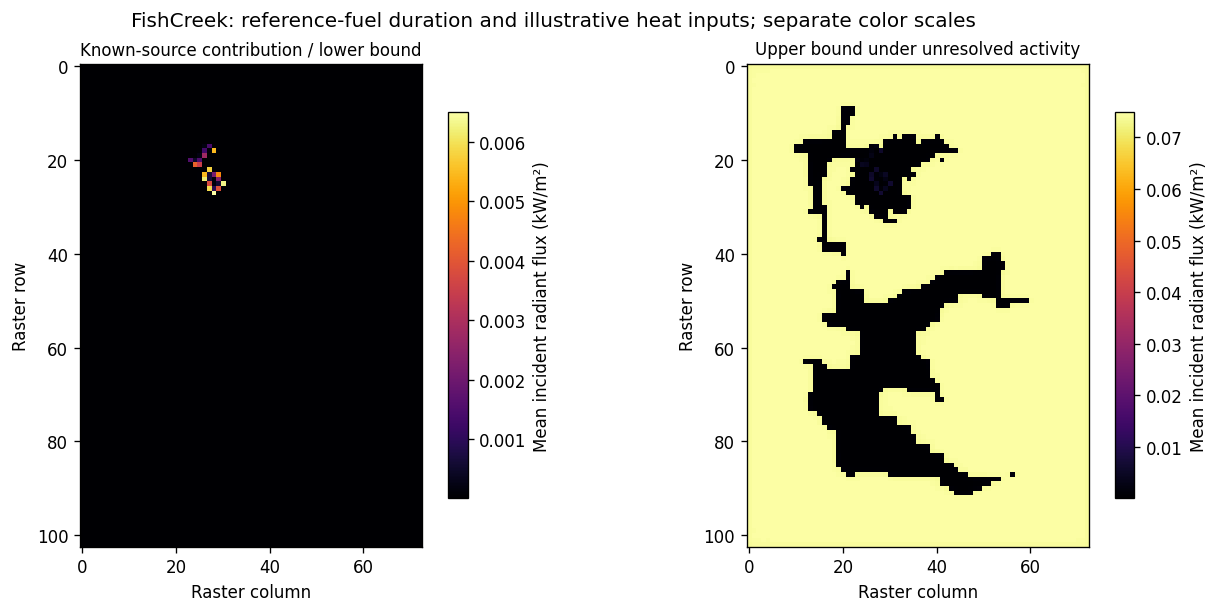

Saved heat, current/endpoint activity, validity, duration and timing arrays to: /Users/movinggk/Documents/영재멘토/WildfireGuardian/demonstration/api_tutorial/runs/run-hn5x0et5


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, values, title in zip(
    axes, (lower_flux, upper_flux),
    ("Known-source contribution / lower bound", "Upper bound under unresolved activity"),
):
    image = ax.imshow(values / 1000.0, origin="upper", cmap="inferno")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Raster column")
    ax.set_ylabel("Raster row")
    fig.colorbar(image, ax=ax, label="Mean incident radiant flux (kW/m²)", shrink=0.8)
fig.suptitle("FishCreek: reference-fuel duration and illustrative heat inputs; separate color scales")
heat_plot_path = OUTPUT_DIR / "heat_bounds.png"
fig.savefig(heat_plot_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

np.savez_compressed(
    OUTPUT_DIR / "heat_outputs.npz",
    complete=heat_details.complete,
    endpoint_complete=heat_details.endpoint_complete,
    mean_flux_w_m2=heat_matrix,
    endpoint_flux_w_m2=heat_details.expected_endpoint_heat_flux_w_m2,
    coordinates_latitude_longitude_deg=heat_coordinates,
    known_source_flux_w_m2=known_flux,
    lower_flux_w_m2=lower_flux,
    upper_flux_w_m2=upper_flux,
    initial_active_burning_probability=heat_details.initial_active_burning_probability,
    initial_burning_valid=heat_details.initial_burning_valid,
    initial_remaining_burning_duration_s=heat_details.initial_remaining_burning_duration_s,
    mean_active_burning_probability=heat_details.mean_active_burning_probability,
    active_burning_valid=heat_details.active_burning_valid,
    endpoint_active_burning_probability=heat_details.endpoint_active_burning_probability,
    endpoint_active_burning_valid=heat_details.endpoint_active_burning_valid,
    burning_duration_s=np.asarray(residence.duration_s),
    duration_fallback_mask=duration_fallback_mask,
    arrival_time_s=arrival_s,
    arrival_valid=arrival_valid,
    current_time_s=current_s,
    incident_energy_j_m2=heat_details.expected_incident_energy_j_m2,
    lower_incident_energy_j_m2=heat_details.incident_energy_lower_bound_j_m2,
    upper_incident_energy_j_m2=heat_details.incident_energy_upper_bound_j_m2,
)
print("Saved heat, current/endpoint activity, validity, duration and timing arrays to:", OUTPUT_DIR)


### Raw inputs and an already computed probability matrix

The heat API also accepts raw burned-area/environment arrays, or a previously computed new-burn probability matrix. The configured grid and projected EPSG supply Earth coordinates. Raw heat processing uses one spatial snapshot; any leading dimensions must be singleton.

The probability bridge receives evaluation probabilities in `[0, 1]`, their validity mask, and a known already-burned mask. Rates in h⁻¹ must first be converted to probability by the model. Known already-burned cells have first-new-burn probability zero even where neighborhood context is unavailable.

Both routes below receive `arrival_time_s`, `current_time_s` and `arrival_valid` in the same event-origin clock as the sample route. They use arrivals only on known already-burned support, derive remaining duration from the configured combustion duration, and never convert retrospective future arrivals into forecast new burning. This explicit timing makes the sample, raw-input and probability-bridge results agree.

Separately supplied `initial_active_burning_probability` and `initial_remaining_burning_duration_s` remain available for independent current-fire information; these inputs replace arrival-derived timing and must refer to known already-burned cells. An `unknown_new_burn_probability` provides a separately justified estimate for unsupported forecast cells and is recorded separately in diagnostics. This demonstration leaves those cells unresolved.

In [15]:
timing_options = {
    "arrival_time_s": arrival_s,
    "current_time_s": current_s,
    "arrival_valid": arrival_valid,
}
raw_heat, raw_heat_coordinates = heat_model.predict(
    sample["burned_area"], sample["features"],
    channel_names=sample["channel_names"],
    burned_area_valid=sample.get("burned_area_valid"),
    feature_valid=sample.get("feature_valid"),
    **timing_options,
)

# The full example has one time step and one prediction channel.
q_matrix = probability.reshape(heat_matrix.shape)
q_valid_matrix = valid.reshape(heat_matrix.shape)
burned_matrix = sample["burned_area"].detach().cpu().numpy().reshape(heat_matrix.shape)
burned_known = np.isfinite(burned_matrix)
if sample.get("burned_area_valid") is not None:
    burned_known &= sample["burned_area_valid"].detach().cpu().numpy().reshape(heat_matrix.shape)
already_burned = burned_known & (burned_matrix == 1)
bridge_options = {
    "probability_valid": q_valid_matrix,
    "already_burned_mask": already_burned,
    **timing_options,
}
bridged_heat, bridged_coordinates = heat_model.predict_from_new_burn_probability(
    q_matrix, **bridge_options,
)
bridged_details = heat_model.predict_from_new_burn_probability_details(
    q_matrix, **bridge_options,
)

for values in (raw_heat, bridged_heat):
    np.testing.assert_allclose(values, heat_matrix, rtol=0, atol=0, equal_nan=True)
for locations in (raw_heat_coordinates, bridged_coordinates):
    np.testing.assert_allclose(locations, heat_coordinates, rtol=0, atol=0, equal_nan=True)
for field in (
    "heat_flux_lower_bound_w_m2", "heat_flux_upper_bound_w_m2",
    "initial_active_burning_probability", "initial_remaining_burning_duration_s",
    "mean_active_burning_probability", "endpoint_active_burning_probability",
):
    np.testing.assert_allclose(
        getattr(bridged_details, field), getattr(heat_details, field),
        rtol=1e-12, atol=1e-8, equal_nan=True,
    )
for field in ("initial_burning_valid", "active_burning_valid", "endpoint_active_burning_valid"):
    np.testing.assert_array_equal(getattr(bridged_details, field), getattr(heat_details, field))
print("Verified: sample, raw-input and probability-bridge heat/activity routes agree.")


Verified: sample, raw-input and probability-bridge heat/activity routes agree.


## 9. Standalone radiation without a wildfire checkpoint

`ExpectedHeatFluxModel.predict(active_burning_probability)` takes a complete, finite `(H, W)` matrix of **probabilities of active burning at the same instant**, all in `[0, 1]`. Its returned heat is instantaneous under those inputs; the composed API above instead returns an interval mean after converting next-hour new-burn probabilities into mean activity.

This independent example specifies a small **synthetic** grid in Korea's projected metric CRS `EPSG:5179`, with a 10 m cell size and explicit first-pixel-corner origin `(1,000,000 m, 2,000,000 m)`. Its grid and probabilities are illustrative, not observations. The returned receiver coordinates still use WGS84 `(latitude, longitude)` in degrees.

In [16]:
active_probability = np.array([[0.0, 0.4, 0.0], [0.1, 0.8, 0.2]], dtype=np.float64)
synthetic_grid = AffineGrid.from_cell_size(
    cell_size_m=10.0,
    origin_xy_m=(1_000_000.0, 2_000_000.0),
    row_direction=-1,
)
# This small synthetic example has its own scalar scenario, independent of the real raster.
synthetic_combustion = CombustionParameters(
    fuel_load_kg_m2=1.0,
    heat_of_combustion_j_kg=18_000_000.0,
    burning_duration_s=120.0,
    consumed_fraction=1.0,
)
radiation = ExpectedHeatFluxModel(
    grid=synthetic_grid,
    epsg=5179,
    heat_release_rate_density_w_m2=synthetic_combustion.heat_release_rate_density_w_m2,
    radiative_fraction=0.3,
    emission_height_m=5.0,
    receiver_height_m=0.0,
    atmospheric_transmissivity=1.0,
)
instantaneous_flux, instantaneous_coordinates = radiation.predict(active_probability)
instantaneous_details = radiation.predict_details(active_probability)
assert instantaneous_flux.shape == active_probability.shape
assert instantaneous_coordinates.shape == (*active_probability.shape, 2)
np.testing.assert_allclose(
    instantaneous_flux, instantaneous_details.incident_heat_flux_w_m2, rtol=1e-12, atol=1e-8,
)
print("Instantaneous incident flux (W/m²):")
display(pd.DataFrame(instantaneous_flux))
print("Synthetic cell (0, 0) latitude/longitude:", instantaneous_coordinates[0, 0])
print("Expected total radiant source power:",
      instantaneous_details.expected_total_radiant_power_w, "W")

# This dose calculation adds a separate constant-flux-for-30-seconds assumption.
constant_flux_dose = instantaneous_details.incident_energy_j_m2(duration_s=30.0)
np.testing.assert_allclose(constant_flux_dose, instantaneous_flux * 30.0)

Instantaneous incident flux (W/m²):


,0,1,2
0,1284.886825,4398.614683,1420.580001
1,2254.659206,7061.411292,2982.565813


Synthetic cell (0, 0) latitude/longitude: [ 37.99995494 127.50005695]
Expected total radiant source power: 6750000.0 W


### Arbitrary receiver points

`predict_at_points` takes receiver **`(x, y)` in metres in the configured projected CRS**, not latitude/longitude. It returns `(flux_values, receiver_coordinates)` with shapes `(N,)` and `(N, 2)`. The latter uses WGS84 `(latitude, longitude)` in degrees. The following receivers are two synthetic cell centers, so their results should agree with the corresponding raster entries.

For a purely local metric grid without a known Earth reference, omit `epsg` and call `predict_details` or `predict_at_points_details`; the tuple methods require georeferencing.

In [17]:
receiver_rows = np.array([0, 1])
receiver_columns = np.array([0, 1])
receiver_xy_m = synthetic_grid.centers(active_probability.shape)[receiver_rows, receiver_columns]
point_flux, point_coordinates = radiation.predict_at_points(active_probability, receiver_xy_m)
assert point_flux.shape == (2,) and point_coordinates.shape == (2, 2)
np.testing.assert_allclose(
    point_flux, instantaneous_flux[receiver_rows, receiver_columns],
    rtol=1e-10, atol=1e-8,
)
np.testing.assert_allclose(
    point_coordinates, instantaneous_coordinates[receiver_rows, receiver_columns],
    rtol=0, atol=1e-10,
)
display(pd.DataFrame({
    "row": receiver_rows,
    "column": receiver_columns,
    "x_projected_m": receiver_xy_m[:, 0],
    "y_projected_m": receiver_xy_m[:, 1],
    "latitude_deg": point_coordinates[:, 0],
    "longitude_deg": point_coordinates[:, 1],
    "incident_flux_w_m2": point_flux,
}))
print("Verified: point receivers agree with the corresponding raster cell centers.")

,row,column,x_projected_m,y_projected_m,latitude_deg,longitude_deg,incident_flux_w_m2
0,0,0,1000005.0,1999995.0,37.999955,127.500057,1284.886825
1,1,1,1000015.0,1999985.0,37.999865,127.500171,7061.411292


Verified: point receivers agree with the corresponding raster cell centers.


## 10. Inspect the duration-aware endpoint flame positions

`heat_details.endpoint_flame_map()` uses the **same residence scenario and continuing-fire timing** as the heat calculation. It estimates active burning **at the end of the next hour**, including any old fire whose remaining duration extends beyond that instant. This differs from the probability of new burning at any time during the hour. Current activity, remaining duration, mean activity and their masks remain in the exported arrays.

The durations come from the aligned reference-fuel raster and the explicitly recorded fallback. The arrivals are retrospective nominal estimates. Neither input establishes measured flame extinction or actual flame geometry. With seconds-long front residence, the modeled current or endpoint selection may be empty; that does not establish absence of real residual flames.

The probability threshold is a selection rule for displaying modeled cell centers; it is not a calibrated detection threshold. The endpoint returns projected positions separately. We look up WGS84 coordinates in the same static matrix.

In [18]:
endpoint_flames = heat_details.endpoint_flame_map()
np.testing.assert_allclose(
    endpoint_flames.probability, heat_details.endpoint_active_burning_probability,
    rtol=0, atol=0, equal_nan=True,
)
MIN_ACTIVE_PROBABILITY = 0.001
positions = endpoint_flames.positions(min_probability=MIN_ACTIVE_PROBABILITY)
cells_rc = positions.cells_rc
selected_coordinates = coordinates[cells_rc[:, 0], cells_rc[:, 1]]
position_table = pd.DataFrame({
    "row": cells_rc[:, 0], "column": cells_rc[:, 1],
    "endpoint_active_probability": positions.probabilities,
    "latitude_deg": selected_coordinates[:, 0], "longitude_deg": selected_coordinates[:, 1],
    "duration_used_explicit_fallback": duration_fallback_mask[cells_rc[:, 0], cells_rc[:, 1]],
})
print("Selected endpoint cells:", len(position_table), "| threshold:", MIN_ACTIVE_PROBABILITY)
print("All positive nominal endpoint probabilities:",
      int(np.count_nonzero(endpoint_flames.valid & (endpoint_flames.probability > 0))))
display(position_table.head(10))


Selected endpoint cells: 0 | threshold: 0.001
All positive nominal endpoint probabilities: 34


,row,column,endpoint_active_probability,latitude_deg,longitude_deg,duration_used_explicit_fallback


## 11. Export arrays and provenance, then verify the saved files

Export both predictions and coordinates together, retaining validity masks and source georeferencing. The source projected coordinates are `(x, y)` in the event's metric CRS; returned coordinates are `(latitude, longitude)` in WGS84 degrees. They are stored under different names.

The heat export includes the complete expectation, known-source contribution, bounds, incident energy, current and endpoint activity, remaining duration, the reference duration map, fallback mask and arrival clock. Unavailable values retain `NaN` with explicit validity masks. The manifest records the checkpoint checksum, input schema, timing, source CRS, physical scenarios, FBFM40 source checksum and residence provenance, library versions and checksums of generated artifacts. It does not certify hashes of every original source raster.

In [19]:
PROBABILITY_FILE = OUTPUT_DIR / "probability.npz"
HEAT_FILE = OUTPUT_DIR / "heat.npz"
probability_arrays = {
    "probability": probability, "valid": valid, diagnostic_name: diagnostic,
    "coordinates_latitude_longitude_deg": coordinates,
    "coordinate_epsg": np.asarray(4326, dtype=np.int64),
    "coordinate_order": np.asarray(["latitude", "longitude"]),
    "source_coordinates_xy_m": sample["coordinates"].numpy(),
    "source_epsg": sample["epsg"].numpy(),
    "affine_transform": sample["affine_transform"].numpy(),
    "time_utc": sample["time_utc"].numpy(), "time_valid": sample["time_valid"].numpy(),
    "pixel_valid": sample["pixel_valid"].numpy(),
}
with PROBABILITY_FILE.open("xb") as stream:
    np.savez_compressed(stream, **probability_arrays)
heat_arrays = {name: getattr(heat_details, name)
               for name in heat_details.__dataclass_fields__
               if isinstance(getattr(heat_details, name), np.ndarray)}
heat_arrays.update(coordinates_latitude_longitude_deg=heat_coordinates,
                   coordinate_epsg=np.asarray(4326, dtype=np.int64),
                   coordinate_order=np.asarray(["latitude", "longitude"]),
                   source_epsg=sample["epsg"].numpy(),
                   affine_transform=sample["affine_transform"].numpy(),
                   complete=np.asarray(heat_details.complete),
                   endpoint_complete=np.asarray(heat_details.endpoint_complete),
                   burning_duration_s=np.asarray(residence.duration_s),
                   duration_fallback_mask=duration_fallback_mask,
                   arrival_time_s=arrival_s, arrival_valid=arrival_valid,
                   current_time_s=np.asarray(current_s))
with HEAT_FILE.open("xb") as stream:
    np.savez_compressed(stream, **heat_arrays)

with np.load(PROBABILITY_FILE, allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved["probability"], probability)
    np.testing.assert_array_equal(saved["coordinates_latitude_longitude_deg"], coordinates)
    assert saved["coordinates_latitude_longitude_deg"].shape == (H, W, 2)
with np.load(HEAT_FILE, allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['expected_heat_flux_w_m2'], heat_matrix)
    np.testing.assert_array_equal(saved["coordinates_latitude_longitude_deg"], coordinates)
    for field in ("initial_active_burning_probability", "initial_remaining_burning_duration_s",
                  "initial_burning_valid", "endpoint_active_burning_probability", "endpoint_active_burning_valid"):
        np.testing.assert_array_equal(saved[field], getattr(heat_details, field))
    np.testing.assert_array_equal(saved["burning_duration_s"], residence.duration_s)
    np.testing.assert_array_equal(saved["duration_fallback_mask"], duration_fallback_mask)
position_table.to_csv(OUTPUT_DIR / "illustrative_endpoint_flame_positions.csv", index=False)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "event": EVENT, "cutoff_utc": CUTOFF, "source_epsg": int(sample["epsg"]),
    "checkpoint": str(CHECKPOINT.relative_to(ROOT)), "checkpoint_sha256": model.checkpoint_sha256,
    "channel_names": list(model.channel_names), "model_contract": model.contract,
    "probability_shape": list(probability.shape), "coordinate_shape": list(coordinates.shape),
    "coordinate_order": ["latitude", "longitude"], "coordinate_epsg": 4326,
    "known_prediction_cells": int(valid.sum()), "unknown_prediction_cells": int((~valid).sum()),
    "heat_complete": bool(heat_details.complete), "heat_metadata": heat_details.metadata,
    "heat_parameters": {
        "scenario": "reference-fuel residence and retrospective arrival; illustrative heat/consumption inputs",
        "fuel_load_kg_m2": np.asarray(combustion.fuel_load_kg_m2).tolist(),
        "heat_of_combustion_j_kg": np.asarray(combustion.heat_of_combustion_j_kg).tolist(),
        "burning_duration_s": {
            "minimum": float(residence.duration_s.min()), "maximum": float(residence.duration_s.max()),
            "array_file": "heat.npz", "array_key": "burning_duration_s",
        },
        "residence_time_provenance": residence.provenance_dict(),
        "consumed_fraction": np.asarray(combustion.consumed_fraction).tolist(),
        "radiative_fraction": np.asarray(heat_model.heat_model.radiative_fraction).tolist(),
        "emission_height_m": heat_model.heat_model.emission_height_m,
        "receiver_height_m": heat_model.heat_model.receiver_height_m,
        "atmospheric_transmissivity": heat_model.heat_model.atmospheric_transmissivity,
        "forecast_interval_s": heat_model.interval_s,
        "conditional_first_new_burn_time": "uniform within the forecast hour",
        "present_active_sources": "known burned-cell activity from nominal arrival age and modeled duration",
        "known_initial_active_cells": heat_details.metadata["known_initial_active_cells"],
        "explicit_duration_fallback_cells": int(duration_fallback_mask.sum()),
    },
    "python": sys.version.split()[0],
    "versions": {p: version(p) for p in ["numpy", "torch", "pandas", "pyproj", "rasterio"]},
    "artifacts": {p.name: {"sha256": sha256(p), "bytes": p.stat().st_size}
                  for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file()},
    "verified": ["raw/sample probability equivalence", "static coordinates across T",
                 "batch coordinate alignment", "spatial-padding coordinates",
                 "save/reload equivalence", "wildfire/heat coordinate alignment",
                 "heat tuple/details equivalence", "sample/raw/probability-bridge activity equivalence",
                 "endpoint flame-map consistency", "current/endpoint activity and duration export readback"],
    "limitations": ["retrospective reconstructed current burned state",
                    "reference-fuel front residence is not measured event-specific extinguishment",
                    "explicit duration fallback on missing/nonburnable/unsupported fuel codes",
                    "retrospective point-arrival uncertainty not integrated",
                    "illustrative fuel consumption and heat parameters",
                    "incomplete full-domain heat expectation",
                    "not a forecast-skill or measured-heat validation"],
}
MANIFEST_FILE = OUTPUT_DIR / "manifest.json"
MANIFEST_FILE.write_text(json.dumps(manifest, indent=2) + "\n")
display(pd.DataFrame([{"file": p.name, "bytes": p.stat().st_size}
                      for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file()]))
print("Verified output directory:", OUTPUT_DIR)

,file,bytes
0,heat.npz,508186
1,heat_bounds.png,76884
2,heat_outputs.npz,396463
3,illustrative_endpoint_flame_positions.csv,98
4,manifest.json,51867
5,model.pt,65284
6,probability.npz,101803
7,probability_and_coordinates.png,127641


Verified output directory: /Users/movinggk/Documents/영재멘토/WildfireGuardian/demonstration/api_tutorial/runs/run-hn5x0et5


## 12. Optional: train a new model from an existing prepared cache

The main tutorial uses a saved checkpoint. Set `RUN_TRAINING=True` below only when you want to fit a new model. The default execution **does not run training**. The three-epoch example demonstrates the call and does not reproduce the saved 30-epoch experiment or establish performance.

The cache supplies `metadata.json`, `train.npz`, `validation.npz`, and `test.npz`. Metadata fixes input channels, kernel size, and explicit split unit and partition memberships. The trainer fits normalization on training rows, selects its checkpoint on validation, and reports test metrics afterward. The weighted split shares fires between training and validation with disjoint cell-hour rows; original test fires stay separate. Preserve these memberships and use a fresh experiment. `output_dir` must be new or empty.

The default family is `exponential`. Changing training settings or data defines a new experiment.

New fitting keeps categorical indicators at raw 0/1 and uses capped inverse-square-root weights based on category presence in training input patches. Validation selection and reported population metrics retain the original inverse inclusion weights. The example specifies the default adjustment explicitly; `categorical_balance="none"` disables only that loss adjustment. The saved training audit and per-category population metrics are available in the experiment outputs.


In [20]:
from wildfire import TrainingConfig
from wildfire import WildfireModel

RUN_TRAINING = False
PREPARED = (ROOT / 'runs'
            / "20261009_weighted_stratified_split/prepared_all")
required_cache_files = ("metadata.json", "train.npz", "validation.npz", "test.npz")
if RUN_TRAINING:
    assert all((PREPARED / name).is_file() for name in required_cache_files)
    experiment = Path(tempfile.mkdtemp(prefix="training-", dir=OUTPUT_DIR))
    trained = WildfireModel.train(
        prepared_data=PREPARED, output_dir=experiment / "fitted", family="exponential",
        config=TrainingConfig(epochs=3, patience=2, batch_size=1024, device="cpu", threads=4,
                              categorical_balance="inverse-sqrt",
                              categorical_balance_min_frequency=0.001,
                              categorical_balance_max_factor=10.0),
    )
    trained.save(experiment / "model.pt")
    print("New training experiment:", experiment)
    print("Returned metric sections:", list(trained.training_metrics))
else:
    print("Optional training skipped: RUN_TRAINING=False. No model was fitted by this execution.")

Optional training skipped: RUN_TRAINING=False. No model was fitted by this execution.


## 13. API reference and interpretation

| Task | Public interface |
| --- | --- |
| Open data with a custom exploration schema | `load_data(...)` |
| Load a saved checkpoint | `load_model(...)` / `WildfireModel.from_checkpoint(...)` |
| Open data with the checkpoint's exact schema | `model.load_data(...)` |
| Predict probability and static Earth coordinates | `model.predict_sample(...)` / `model.predict(...)` |
| Retrieve probability, masks, and raw score/rate | `model.predict_sample_details(...)` / `model.predict_details(...)` |
| Retrieve only probabilities | `model.predict_proba(...)` |
| Move resident model and normalization | `model.to(device)` |
| Save resident parameters | `model.save(path)` |
| Compose wildfire and heat models | `model.heat_model(...)` / `WildfireHeatModel.from_checkpoint(...)` |
| Predict mean radiant heat and coordinates | `heat_model.predict_sample(...)`, `predict(...)`, `predict_from_new_burn_probability(...)` |
| Retrieve heat bounds, dose, and provenance | The corresponding heat `*_details(...)` methods |
| Compute instantaneous radiation from complete active probabilities | `ExpectedHeatFluxModel.predict(...)` / `predict_at_points(...)` |
| Estimate next-hour active-flame locations | `model.predict_active_flames_sample(...)` |
| Fit from an explicitly prepared cache | `WildfireModel.train(..., config=TrainingConfig(...))` |

Do not interpret missing probability or heat values as zero. New cumulative burning, instantaneous activity, interval-mean heat flux (W/m²), and interval incident energy (J/m²) are different quantities. Positions are representative grid centers under the saved geometry and stated physical assumptions.

For alternate checkpoints, events, and full scientific/source discussion, use the [root README](README.md), [data contracts](README.md#data-guide), [saved reports](README.md#completed-reports), and [radiation references](wildfire/heat_sources.json).